In [ ]:
# ============================================================
# TASK 7 - LSTM ELECTRICITY CONSUMPTION FORECASTING
# STEP 1: SETUP AND LOAD CLEANED DATA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import joblib

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

# Check GPU
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU detected:", gpus)
else:
    print("No GPU detected - CPU will be used.")


# ------------------------------------------------------------
# LOAD CLEANED DATASET FROM TASK 4
# ------------------------------------------------------------

df = pd.read_csv(
    "/content/household_power_cleaned.csv",
    parse_dates=["Datetime"]
)

print("\nDataset loaded successfully!")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

TensorFlow version: 2.20.0
No GPU detected - CPU will be used.

Dataset loaded successfully!

Shape:
(361507, 8)

Columns:
['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Missing values:
Datetime                 0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         1
Sub_metering_1           1
Sub_metering_2           1
Sub_metering_3           1
dtype: int64

First 5 rows:


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [ ]:
# ============================================================
# STEP 2: KEEP THE TIME-SERIES DATA NEEDED FOR LSTM
# ============================================================

power_df = df[
    ["Datetime", "Global_active_power"]
].copy()

# Sort chronologically
power_df = power_df.sort_values("Datetime")

# Make Datetime the index
power_df = power_df.set_index("Datetime")

print("Original minute-level data:")
print("Shape:", power_df.shape)

print("\nDate range:")
print("Start:", power_df.index.min())
print("End  :", power_df.index.max())

display(power_df.head())

Original minute-level data:
Shape: (361507, 1)

Date range:
Start: 2006-12-16 17:24:00
End  : 2007-08-24 18:30:00


,Global_active_power
Datetime,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


In [ ]:
# ============================================================
# STEP 3: RESAMPLE TO 15-MINUTE INTERVALS
# ============================================================

power_15min = power_df.resample("15min").mean()

# Fill any small gaps after resampling
power_15min["Global_active_power"] = (
    power_15min["Global_active_power"]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

print("Original minute-level rows:")
print(len(power_df))

print("\n15-minute rows:")
print(len(power_15min))

print("\nMissing values:")
print(power_15min.isnull().sum())

print("\nFirst 10 resampled values:")
display(power_15min.head(10))

Original minute-level rows:
361507

15-minute rows:
24102

Missing values:
Global_active_power    0
dtype: int64

First 10 resampled values:


,Global_active_power
Datetime,
2006-12-16 17:15:00,4.587333
2006-12-16 17:30:00,4.140667
2006-12-16 17:45:00,4.159333
2006-12-16 18:00:00,4.121067
2006-12-16 18:15:00,3.768533
2006-12-16 18:30:00,3.127600
2006-12-16 18:45:00,3.511600
2006-12-16 19:00:00,3.484533
2006-12-16 19:15:00,3.444267


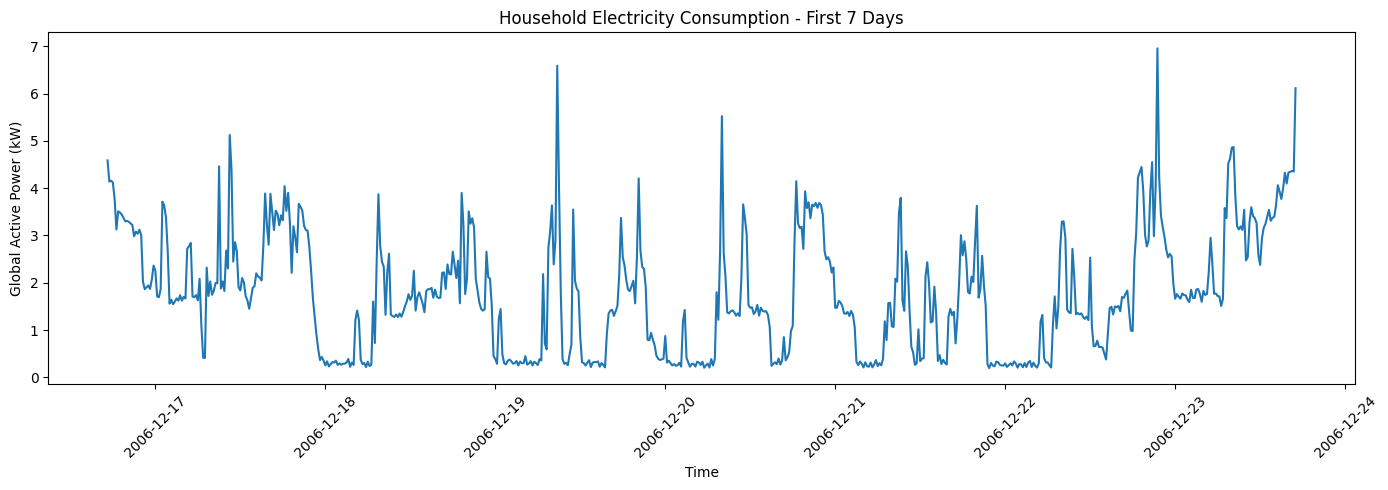

In [ ]:
# ============================================================
# STEP 4: VISUALIZE ELECTRICITY CONSUMPTION
# ============================================================

# Plot only the first 7 days so the pattern is visible
first_week = power_15min.iloc[:96 * 7]

plt.figure(figsize=(14, 5))

plt.plot(
    first_week.index,
    first_week["Global_active_power"]
)

plt.title("Household Electricity Consumption - First 7 Days")
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 5: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Convert the power column to a NumPy array
power_values = power_15min["Global_active_power"].values.reshape(-1, 1)

total_samples = len(power_values)

# 70% training
train_end = int(total_samples * 0.70)

# Next 15% validation
val_end = int(total_samples * 0.85)

print("Total 15-minute readings:", total_samples)

print("\nTRAIN")
print("Start index : 0")
print("End index   :", train_end)
print("Samples     :", train_end)

print("\nVALIDATION")
print("Start index :", train_end)
print("End index   :", val_end)
print("Samples     :", val_end - train_end)

print("\nTEST")
print("Start index :", val_end)
print("End index   :", total_samples)
print("Samples     :", total_samples - val_end)

print("\nDate ranges:")

print(
    "Train:",
    power_15min.index[0],
    "to",
    power_15min.index[train_end - 1]
)

print(
    "Validation:",
    power_15min.index[train_end],
    "to",
    power_15min.index[val_end - 1]
)

print(
    "Test:",
    power_15min.index[val_end],
    "to",
    power_15min.index[-1]
)

Total 15-minute readings: 24102

TRAIN
Start index : 0
End index   : 16871
Samples     : 16871

VALIDATION
Start index : 16871
End index   : 20486
Samples     : 3615

TEST
Start index : 20486
End index   : 24102
Samples     : 3616

Date ranges:
Train: 2006-12-16 17:15:00 to 2007-06-10 10:45:00
Validation: 2007-06-10 11:00:00 to 2007-07-18 02:30:00
Test: 2007-07-18 02:45:00 to 2007-08-24 18:30:00


In [ ]:
# ============================================================
# STEP 6: SCALE DATA
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data
scaler.fit(power_values[:train_end])

# Apply the same scaler to the complete time series
power_scaled = scaler.transform(power_values)

print("Scaling completed.")

print("\nOriginal first 5 values:")
print(power_values[:5].flatten())

print("\nScaled first 5 values:")
print(power_scaled[:5].flatten())

print("\nTraining mean used by scaler:")
print(scaler.mean_[0])

print("\nTraining standard deviation:")
print(scaler.scale_[0])

Scaling completed.

Original first 5 values:
[4.58733333 4.14066667 4.15933333 4.12106667 3.76853333]

Scaled first 5 values:
[2.86470539 2.47958886 2.49568328 2.46268971 2.15873505]

Training mean used by scaler:
1.2647846995831111

Training standard deviation:
1.1598221047304973


In [ ]:
# ============================================================
# STEP 7: DEFINE LSTM INPUT AND FORECAST HORIZON
# ============================================================

SEQUENCE_LENGTH = 96
FORECAST_HORIZON = 4

print("Sequence length:", SEQUENCE_LENGTH)
print(
    "Past history used:",
    SEQUENCE_LENGTH * 15 / 60,
    "hours"
)

print("\nForecast horizon:", FORECAST_HORIZON)
print(
    "Prediction made:",
    FORECAST_HORIZON * 15,
    "minutes into the future"
)

Sequence length: 96
Past history used: 24.0 hours

Forecast horizon: 4
Prediction made: 60 minutes into the future


In [ ]:
# ============================================================
# STEP 8: CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(
    data,
    target_start,
    target_end,
    sequence_length=96,
    forecast_horizon=4
):

    X = []
    y = []
    target_indices = []

    for target_index in range(target_start, target_end):

        # Latest value the model is allowed to know
        sequence_end = target_index - forecast_horizon + 1

        # Beginning of the 24-hour sequence
        sequence_start = sequence_end - sequence_length

        # Skip if there is not enough previous history
        if sequence_start < 0:
            continue

        sequence = data[
            sequence_start:sequence_end
        ]

        target = data[target_index]

        X.append(sequence)
        y.append(target)
        target_indices.append(target_index)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(target_indices)
    )


# ------------------------------------------------------------
# TRAINING SEQUENCES
# ------------------------------------------------------------

X_train, y_train, train_indices = create_sequences(
    power_scaled,
    target_start=SEQUENCE_LENGTH + FORECAST_HORIZON - 1,
    target_end=train_end,
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


# ------------------------------------------------------------
# VALIDATION SEQUENCES
# ------------------------------------------------------------

X_val, y_val, val_indices = create_sequences(
    power_scaled,
    target_start=train_end,
    target_end=val_end,
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


# ------------------------------------------------------------
# TEST SEQUENCES
# ------------------------------------------------------------

X_test, y_test, test_indices = create_sequences(
    power_scaled,
    target_start=val_end,
    target_end=len(power_scaled),
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


print("Sequence creation completed!\n")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

Sequence creation completed!

X_train: (16772, 96, 1)
y_train: (16772, 1)

X_val: (3615, 96, 1)
y_val: (3615, 1)

X_test: (3616, 96, 1)
y_test: (3616, 1)


In [ ]:
# ============================================================
# STEP 8: CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(
    data,
    target_start,
    target_end,
    sequence_length=96,
    forecast_horizon=4
):

    X = []
    y = []
    target_indices = []

    for target_index in range(target_start, target_end):

        # Latest value the model is allowed to know
        sequence_end = target_index - forecast_horizon + 1

        # Beginning of the 24-hour sequence
        sequence_start = sequence_end - sequence_length

        # Skip if there is not enough previous history
        if sequence_start < 0:
            continue

        sequence = data[
            sequence_start:sequence_end
        ]

        target = data[target_index]

        X.append(sequence)
        y.append(target)
        target_indices.append(target_index)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(target_indices)
    )


# ------------------------------------------------------------
# TRAINING SEQUENCES
# ------------------------------------------------------------

X_train, y_train, train_indices = create_sequences(
    power_scaled,
    target_start=SEQUENCE_LENGTH + FORECAST_HORIZON - 1,
    target_end=train_end,
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


# ------------------------------------------------------------
# VALIDATION SEQUENCES
# ------------------------------------------------------------

X_val, y_val, val_indices = create_sequences(
    power_scaled,
    target_start=train_end,
    target_end=val_end,
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


# ------------------------------------------------------------
# TEST SEQUENCES
# ------------------------------------------------------------

X_test, y_test, test_indices = create_sequences(
    power_scaled,
    target_start=val_end,
    target_end=len(power_scaled),
    sequence_length=SEQUENCE_LENGTH,
    forecast_horizon=FORECAST_HORIZON
)


print("Sequence creation completed!\n")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

Sequence creation completed!

X_train: (16772, 96, 1)
y_train: (16772, 1)

X_val: (3615, 96, 1)
y_val: (3615, 1)

X_test: (3616, 96, 1)
y_test: (3616, 1)


In [ ]:
# ============================================================
# STEP 10: BUILD THE LSTM MODEL
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.regularizers import l2

model = Sequential([

    # --------------------------------------------------------
    # First LSTM layer
    # --------------------------------------------------------
    LSTM(
        64,
        return_sequences=True,
        input_shape=(SEQUENCE_LENGTH, 1)
    ),

    # Randomly disables 20% of neurons during training
    Dropout(0.20),

    # --------------------------------------------------------
    # Second LSTM layer
    # --------------------------------------------------------
    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(0.20),

    # --------------------------------------------------------
    # Dense layer
    # --------------------------------------------------------
    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),

    # --------------------------------------------------------
    # Final output
    # --------------------------------------------------------
    Dense(1)
])


# Show model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 96, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# STEP 11: COMPILE THE LSTM MODEL
# ============================================================

from tensorflow.keras.optimizers import Adam

optimizer = Adam(
    learning_rate=0.001
)

model.compile(
    optimizer=optimizer,
    loss="mse",
    metrics=["mae"]
)

print("Model compiled successfully!")
print("Optimizer     : Adam")
print("Learning Rate : 0.001")
print("Loss Function : Mean Squared Error (MSE)")
print("Metric        : Mean Absolute Error (MAE)")

Model compiled successfully!
Optimizer     : Adam
Learning Rate : 0.001
Loss Function : Mean Squared Error (MSE)
Metric        : Mean Absolute Error (MAE)


In [ ]:
# ============================================================
# STEP 12: TRAINING CALLBACKS
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate if improvement stops
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [ ]:
# ============================================================
# STEP 13: TRAIN THE LSTM MODEL
# ============================================================

history = model.fit(

    X_train,
    y_train,

    # Validation data is NOT used to update weights.
    # It is only used to check performance during training.
    validation_data=(X_val, y_val),

    epochs=50,

    batch_size=256,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    # Keep chronological order for time-series data
    shuffle=False,

    verbose=1
)

print("\nTraining completed!")

Epoch 1/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 331ms/step - loss: 0.7763 - mae: 0.6700 - val_loss: 0.4338 - val_mae: 0.5087 - learning_rate: 0.0010
Epoch 2/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 313ms/step - loss: 0.6925 - mae: 0.6158 - val_loss: 0.4265 - val_mae: 0.4983 - learning_rate: 0.0010
Epoch 3/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 293ms/step - loss: 0.6642 - mae: 0.5991 - val_loss: 0.4174 - val_mae: 0.4845 - learning_rate: 0.0010
Epoch 4/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 310ms/step - loss: 0.6540 - mae: 0.5858 - val_loss: 0.4140 - val_mae: 0.4851 - learning_rate: 0.0010
Epoch 5/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 41s 312ms/step - loss: 0.6411 - mae: 0.5787 - val_loss: 0.4108 - val_mae: 0.4843 - learning_rate: 0.0010
Epoch 6/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 293ms/step - loss: 0.6325 - mae: 0.5717 - val_loss: 0.4012 - val_mae: 0.4684 - learning_rate: 0.0010
Epoch 7/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 312ms/step - loss: 0.6130 - mae: 0.5526 - val_loss: 0.3779 - val_mae: 0.4424 - learning_rate: 0.0010

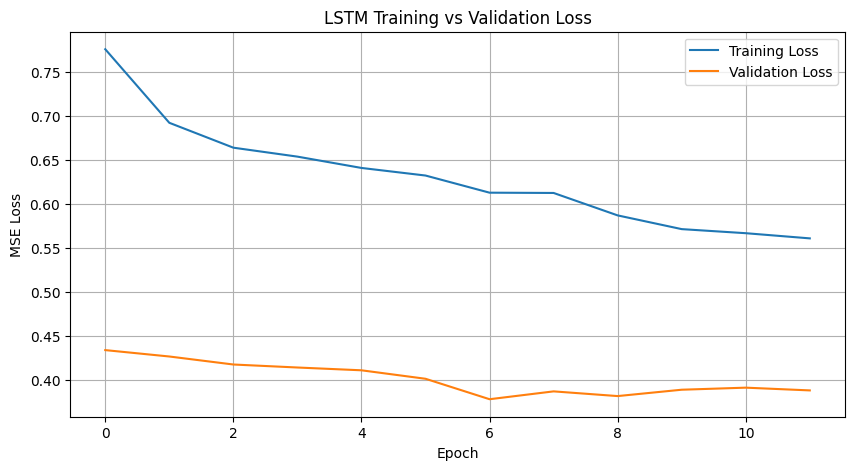

In [ ]:
# ============================================================
# STEP 14: TRAINING AND VALIDATION CURVES
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# STEP 15: FINAL TEST SET EVALUATION
# ============================================================

# Predict scaled values
y_pred_scaled = model.predict(
    X_test,
    verbose=1
)

# ------------------------------------------------------------
# Convert predictions back to actual kW
# ------------------------------------------------------------

y_pred = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

# Convert actual test targets back to kW
y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()


# ------------------------------------------------------------
# CALCULATE REGRESSION METRICS
# ------------------------------------------------------------

mae = mean_absolute_error(
    y_actual,
    y_pred
)

mse = mean_squared_error(
    y_actual,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_actual,
    y_pred
)


print("=" * 60)
print("FINAL LSTM TEST PERFORMANCE")
print("=" * 60)

print(f"MAE  : {mae:.4f} kW")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f} kW")
print(f"R²   : {r2:.4f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step
FINAL LSTM TEST PERFORMANCE
MAE  : 0.5026 kW
MSE  : 0.4467
RMSE : 0.6684 kW
R²   : 0.2676


In [ ]:
# ============================================================
# STEP 16: SHOW SAMPLE LSTM PREDICTIONS
# ============================================================

sample_results = pd.DataFrame({

    "Actual_Power_kW":
        y_actual[:15],

    "Predicted_Power_kW":
        y_pred[:15]
})

sample_results["Absolute_Error_kW"] = abs(
    sample_results["Actual_Power_kW"]
    - sample_results["Predicted_Power_kW"]
)

display(
    sample_results.round(4)
)

,Actual_Power_kW,Predicted_Power_kW,Absolute_Error_kW
0,0.1903,0.4136,0.2233
1,0.1985,0.4074,0.2089
2,0.1620,0.3956,0.2336
3,0.2347,0.3898,0.1552
4,0.2201,0.3883,0.1682
5,0.3228,0.3915,0.0687
6,0.2091,0.3958,0.1867
7,0.2783,0.4137,0.1354
8,0.2003,0.4384,0.2381
9,0.1944,0.4844,0.2900


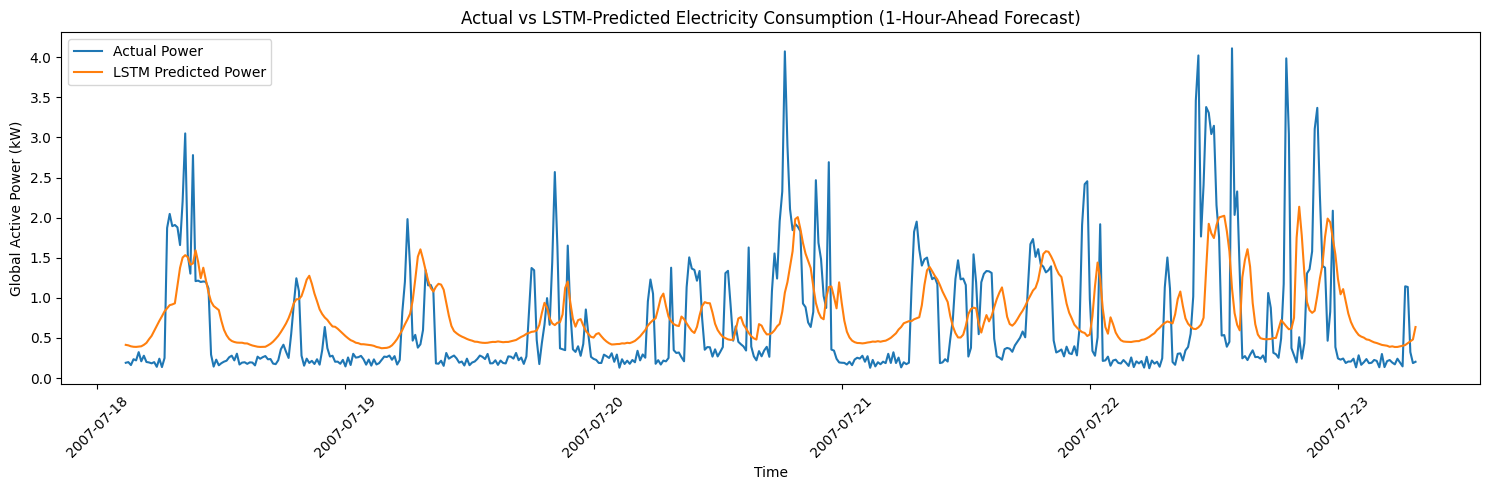

In [ ]:
# ============================================================
# STEP 17: ACTUAL VS PREDICTED POWER
# ============================================================

# Show first 500 test predictions
n = 500

test_times = power_15min.index[
    test_indices[:n]
]

plt.figure(figsize=(15, 5))

plt.plot(
    test_times,
    y_actual[:n],
    label="Actual Power"
)

plt.plot(
    test_times,
    y_pred[:n],
    label="LSTM Predicted Power"
)

plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.title(
    "Actual vs LSTM-Predicted Electricity Consumption "
    "(1-Hour-Ahead Forecast)"
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()